# UTS Graf Sains Data: Neo4j, VSM, Similarity, dan Rekomendasi KNN

**Nama:** Intan Ayu Lestari  |  **NIM:** 23031554051  |  **Kelas:** 2023B

**Dataset:** RetailRocket e-commerce (`events.csv`)

| Fold | Periode | File |
|---|---|---|
| Training (P1) | 11 Mei 2015 s.d. 11 Juli 2015 | `events_train.csv` |
| Testing (P2)  | 20 Juli 2015 s.d. 4 Agustus 2015 | `events_test.csv` |



## 0. Persiapan

In [1]:
from pathlib import Path
import os
import getpass

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from IPython.display import display

SEED = 42                       
TULIS_KE_NEO4J = False         

DATA_DIR = Path("../data")
if not DATA_DIR.exists():
    DATA_DIR = Path("data")
TRAIN_FILE = DATA_DIR / "events_train.csv"
TEST_FILE = DATA_DIR / "events_test.csv"

print("Folder data:", DATA_DIR.resolve())

Folder data: C:\Users\DELL\Downloads\uts-gsd\proyek-gsd\data


### Koneksi Neo4j
Fungsi `cypher()` menjalankan query dan mengembalikan `DataFrame`. Jika server Neo4j tidak terhubung, sel yang memakainya dilewati sehingga bagian Python tetap bisa dijalankan.

In [2]:
from neo4j import GraphDatabase

NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USER = "neo4j"
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD") or getpass.getpass("Password Neo4j: ")


def connect():
    try:
        d = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
        d.verify_connectivity()
        print("Koneksi Neo4j berhasil.")
        return d
    except Exception as e:
        print("Neo4j tidak terhubung, sel Neo4j akan dilewati.\nPenyebab:", e)
        return None


driver = connect()


def cypher(query, **params):
    """Jalankan query Cypher, kembalikan DataFrame (None jika Neo4j tidak terhubung)."""
    if driver is None:
        print("(dilewati: Neo4j tidak terhubung)")
        return None
    records, _, _ = driver.execute_query(query, database_="neo4j", **params)
    return pd.DataFrame([r.data() for r in records])

Koneksi Neo4j berhasil.


## 2.1 Wrangling dan EDA

### No. 1 dan 2: Periode waktu dan filter

Kolom `timestamp` pada dataset berupa **Unix epoch dalam milidetik**, sehingga dikonversi dengan `unit="ms"` (zona waktu UTC). Filter dilakukan oleh `filter_events.py` dengan batas awal inklusif dan batas akhir eksklusif (`>= 11 Mei` dan `< 12 Juli` untuk training, `>= 20 Juli` dan `< 5 Agustus` untuk testing), sehingga tanggal akhir ikut terhitung penuh. Hasilnya disimpan ke `events_train.csv` dan `events_test.csv`. Sel di bawah memverifikasi hasil filter tersebut.

In [3]:
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

for nama, d in [("Training", train_df), ("Testing", test_df)]:
    waktu = pd.to_datetime(d["timestamp"], unit="ms", utc=True)
    print(f"{nama:9s}: {len(d):>9,} baris | {waktu.min()}  ->  {waktu.max()}")
    print("          event:", d["event"].value_counts().to_dict())

Training : 1,289,106 baris | 2015-05-11 00:00:01.166000+00:00  ->  2015-07-11 23:59:57.604000+00:00
          event: {'view': 1247130, 'addtocart': 31573, 'transaction': 10403}
Testing  :   362,278 baris | 2015-07-20 00:00:03.875000+00:00  ->  2015-08-04 23:59:45.149000+00:00
          event: {'view': 349839, 'addtocart': 9331, 'transaction': 3108}


### No. 3: Komposisi subgraph (jenis dan jumlah simpul)

Hanya data **training** yang diimpor ke Neo4j, sehingga subgraph terdiri atas simpul `Visitor` dan `Item` dengan tiga jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`). Query dijalankan lewat Python API (`driver.execute_query`).

**Penjelasan Cypher:**
- `MATCH (n)` mencocokkan seluruh simpul pada graf.
- `labels(n)[0]` mengambil nama label simpul (`Visitor` atau `Item`).
- `count(*)` menghitung jumlah baris, dan karena `labels(n)[0]` ikut di `RETURN`, hasil otomatis dikelompokkan per label (*implicit group by*).
- `MATCH ()-[r]->()` mencocokkan seluruh relasi berarah dan `type(r)` mengambil jenisnya.
- `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.

In [6]:
Q_NODES = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
"""
Q_RELS = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""

komposisi_simpul = cypher(Q_NODES)
komposisi_relasi = cypher(Q_RELS)
display(komposisi_simpul)
display(komposisi_relasi)

# Pembanding dari pandas: setiap event menjadi satu relasi (CREATE), setiap ID unik menjadi satu simpul
pembanding = pd.DataFrame({
    "jenis": ["Visitor", "Item", "VIEWED", "ADDED_TO_CART", "BOUGHT"],
    "jumlah_dari_csv": [
        train_df["visitorid"].nunique(), train_df["itemid"].nunique(),
        (train_df["event"] == "view").sum(),
        (train_df["event"] == "addtocart").sum(),
        (train_df["event"] == "transaction").sum(),
    ],
})
print("Nilai yang seharusnya muncul (dihitung langsung dari CSV training):")
display(pembanding)

,jenis_simpul,jumlah
0,Visitor,653133
1,Item,169533


,jenis_relasi,jumlah
0,VIEWED,1247130
1,ADDED_TO_CART,31573
2,BOUGHT,10403
3,SIMILAR_TO,5


Nilai yang seharusnya muncul (dihitung langsung dari CSV training):


,jenis,jumlah_dari_csv
0,Visitor,653133
1,Item,169533
2,VIEWED,1247130
3,ADDED_TO_CART,31573
4,BOUGHT,10403


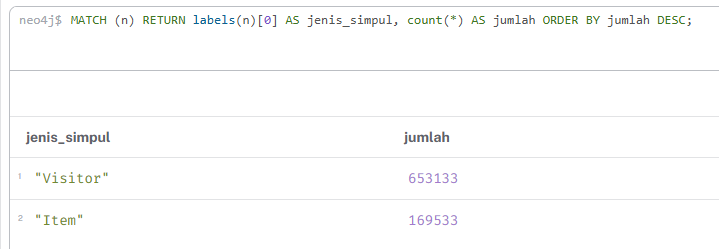

In [10]:
from IPython.display import Image, display
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1244).png"))

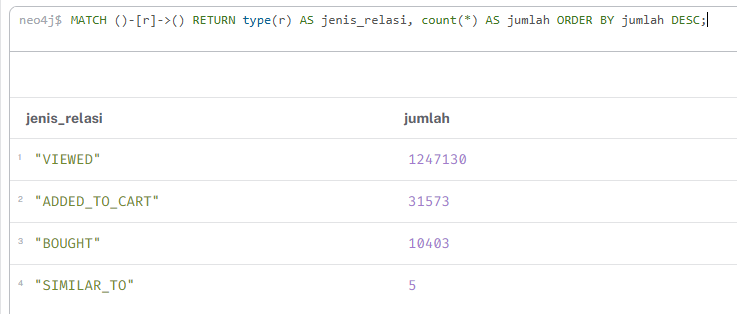

In [11]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1245).png"))

**Interpretasi:** graf bersifat *bipartit* dan berarah (Visitor → Item). Jumlah simpul `Visitor` dan `Item` pada Neo4j harus sama dengan jumlah ID unik pada CSV training, dan jumlah tiap relasi sama dengan jumlah event sejenis. Kalau ada relasi `SIMILAR_TO` pada hasil di atas, itu berasal dari langkah similarity di bawah yang sudah pernah dijalankan.

### Membangun matriks VSM (Visitor × Item)

Interaksi diberi bobot implisit: `view` = 1, `addtocart` = 3, `transaction` = 5. Bobot dijumlahkan bila visitor berinteraksi dengan item yang sama berkali-kali. Matriks disimpan dalam format *sparse* (CSR) karena hampir semua selnya nol.

In [12]:
visitor_ids = np.sort(train_df["visitorid"].unique())
item_ids = np.sort(train_df["itemid"].unique())
visitor_to_idx = {v: i for i, v in enumerate(visitor_ids)}
item_to_idx = {x: i for i, x in enumerate(item_ids)}

event_weights = {"view": 1, "addtocart": 3, "transaction": 5}
bobot = train_df["event"].map(event_weights).to_numpy()

VSM = sp.coo_matrix(
    (bobot,
     (train_df["visitorid"].map(visitor_to_idx).to_numpy(),
      train_df["itemid"].map(item_to_idx).to_numpy())),
    shape=(len(visitor_ids), len(item_ids)),
).tocsr()
VSM.sum_duplicates()

VSM_binary = VSM.copy()
VSM_binary.data = np.ones_like(VSM_binary.data)

items_per_visitor = np.diff(VSM_binary.indptr)                       # item unik per visitor
visitors_per_item = np.asarray(VSM_binary.sum(axis=0)).ravel()      # visitor unik per item

print("Dimensi VSM (visitor x item):", VSM.shape)
print("Jumlah pasangan visitor-item (nonzero):", f"{VSM.nnz:,}")

Dimensi VSM (visitor x item): (653133, 169533)
Jumlah pasangan visitor-item (nonzero): 996,072


### No. 4: VSM terhadap simpul **User**

Pada VSM user, setiap **baris** adalah vektor satu user, dan setiap **dimensi** adalah satu item. Jadi dimensi vektor user = jumlah item, dan shape matriks = (jumlah user × jumlah item).

In [13]:
n_user, n_item = VSM.shape
total = n_user * n_item
print("VSM User")
print("  Shape                    :", VSM.shape)
print("  Dimensi tiap vektor user :", n_item, "(= jumlah item)")
print("  Elemen nonzero           :", f"{VSM.nnz:,}")
print("  Total elemen             :", f"{total:,}")
print(f"  Kepadatan                : {VSM.nnz / total:.6%}")
print(f"  Sparsity                 : {1 - VSM.nnz / total:.6%}")
print("  Memori sparse (MB)       :", round((VSM.data.nbytes + VSM.indices.nbytes + VSM.indptr.nbytes) / 1e6, 1))
print("  Memori jika dense (GB)   :", round(total * 8 / 1e9, 1))
print()
print("Item unik per user  -> min:", items_per_visitor.min(),
      "| rata-rata:", round(items_per_visitor.mean(), 2),
      "| median:", int(np.median(items_per_visitor)),
      "| maks:", items_per_visitor.max())
print("User dengan tepat 1 item:", f"{(items_per_visitor == 1).sum():,}",
      f"({(items_per_visitor == 1).mean():.1%} dari seluruh user)")

VSM User
  Shape                    : (653133, 169533)
  Dimensi tiap vektor user : 169533 (= jumlah item)
  Elemen nonzero           : 996,072
  Total elemen             : 110,727,596,889
  Kepadatan                : 0.000900%
  Sparsity                 : 99.999100%
  Memori sparse (MB)       : 14.6
  Memori jika dense (GB)   : 885.8

Item unik per user  -> min: 1 | rata-rata: 1.53 | median: 1 | maks: 1492
User dengan tepat 1 item: 520,840 (79.7% dari seluruh user)


**Plot networkx (sampel).** Seluruh graf terlalu besar untuk digambar, jadi diambil subgraf: 5 item terpopuler dan 8 user acak (seed tetap) dari tiap item tersebut. Graf kiri adalah graf bipartit user-item, graf kanan adalah **proyeksi user-user** (dua user terhubung bila berbagi minimal satu item).

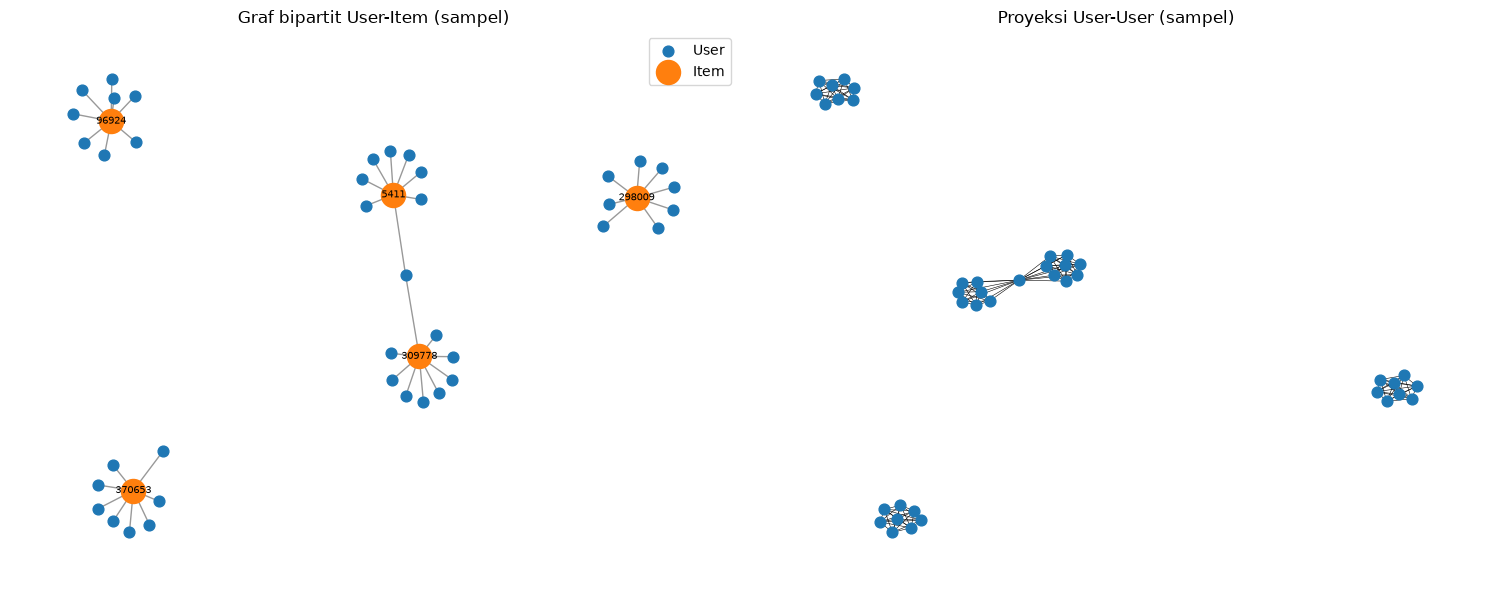

Sampel: 40 user, 5 item, 41 sisi bipartit; proyeksi user-user: 148 sisi


In [14]:
top5_items = np.argsort(-visitors_per_item, kind="stable")[:5]
VSM_csc = VSM_binary.tocsc()
rng = np.random.default_rng(SEED)

sampel_user = set()
for it in top5_items:
    pengguna_item = VSM_csc[:, it].nonzero()[0]
    sampel_user.update(rng.choice(pengguna_item, size=8, replace=False).tolist())
sampel_user = sorted(sampel_user)

sub = VSM_binary[sampel_user][:, top5_items].tocoo()
G = nx.Graph()
for r, c in zip(sub.row, sub.col):
    G.add_edge(f"U{visitor_ids[sampel_user[r]]}", f"I{item_ids[top5_items[c]]}")
user_nodes = [n for n in G if n.startswith("U")]
item_nodes = [n for n in G if n.startswith("I")]

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pos = nx.spring_layout(G, seed=SEED)
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:blue", node_size=60, ax=ax[0], label="User")
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:orange", node_size=300, ax=ax[0], label="Item")
nx.draw_networkx_edges(G, pos, alpha=0.4, ax=ax[0])
nx.draw_networkx_labels(G, pos, labels={n: n[1:] for n in item_nodes}, font_size=7, ax=ax[0])
ax[0].set_title("Graf bipartit User-Item (sampel)"); ax[0].legend(); ax[0].axis("off")

Gu = nx.bipartite.weighted_projected_graph(G, user_nodes)
nx.draw_networkx(Gu, nx.spring_layout(Gu, seed=SEED), node_size=60, with_labels=False, width=0.4, ax=ax[1])
ax[1].set_title("Proyeksi User-User (sampel)"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print("Sampel:", len(user_nodes), "user,", len(item_nodes), "item,", G.number_of_edges(), "sisi bipartit;",
      "proyeksi user-user:", Gu.number_of_edges(), "sisi")

### No. 5: VSM terhadap simpul **Item**

Pada VSM item, setiap vektor adalah satu **kolom** dari VSM user (matriks ditranspos). Dimensi tiap vektor item = jumlah user, dan shape = (jumlah item × jumlah user).

In [15]:
item_vectors = VSM.T.tocsr()
print("VSM Item")
print("  Shape                    :", item_vectors.shape)
print("  Dimensi tiap vektor item :", item_vectors.shape[1], "(= jumlah user)")
print("  Elemen nonzero           :", f"{item_vectors.nnz:,}", "(sama dengan VSM user)")
print()
print("User unik per item  -> min:", int(visitors_per_item.min()),
      "| rata-rata:", round(visitors_per_item.mean(), 2),
      "| median:", int(np.median(visitors_per_item)),
      "| maks:", int(visitors_per_item.max()))
print("Item dengan tepat 1 user:", f"{(visitors_per_item == 1).sum():,}",
      f"({(visitors_per_item == 1).mean():.1%} dari seluruh item)")

VSM Item
  Shape                    : (169533, 653133)
  Dimensi tiap vektor item : 653133 (= jumlah user)
  Elemen nonzero           : 996,072 (sama dengan VSM user)

User unik per item  -> min: 1 | rata-rata: 5.88 | median: 2 | maks: 1181
Item dengan tepat 1 user: 70,506 (41.6% dari seluruh item)


**Proyeksi item-item.** Nilai (i, j) adalah jumlah user yang berinteraksi dengan item i **dan** item j. Visualisasi memakai 15 item terpopuler.

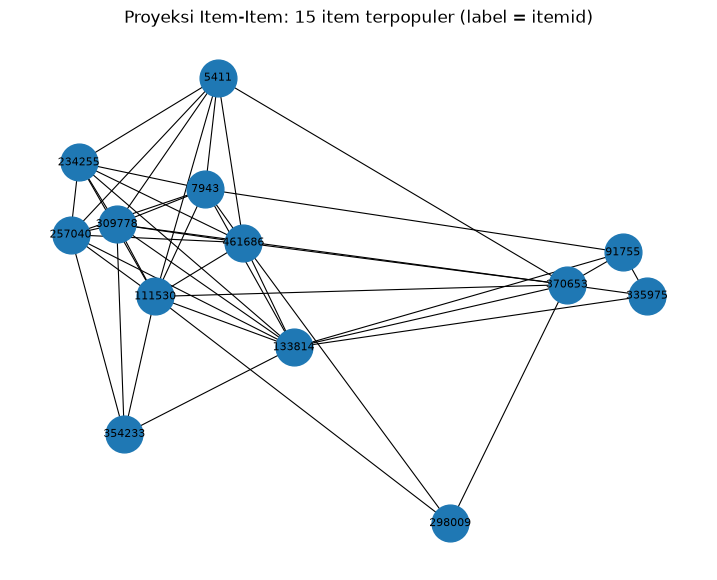

In [16]:
item_projection = (VSM_binary.T @ VSM_binary).tocsr()
item_projection.setdiag(0)
item_projection.eliminate_zeros()

top15 = np.argsort(-visitors_per_item, kind="stable")[:15]
mat = item_projection[top15, :][:, top15].toarray()
Gi = nx.from_numpy_array(mat)
Gi.remove_nodes_from(list(nx.isolates(Gi)))

plt.figure(figsize=(9, 7))
pos = nx.spring_layout(Gi, seed=SEED)
nx.draw_networkx(Gi, pos, labels={n: str(item_ids[top15[n]]) for n in Gi}, node_size=700, font_size=8, width=0.8)
plt.title("Proyeksi Item-Item: 15 item terpopuler (label = itemid)")
plt.axis("off"); plt.show()

### No. 6: Proyeksi mana yang lebih baik?

Dua proyeksi dibandingkan **pada skala penuh** (bukan sampel), memakai matriks biner, agar perbandingannya adil. Proyeksi user-user penuh memakai sekitar 1 GB memori, jadi sel ini bisa memakan waktu beberapa puluh detik.

In [17]:
def ringkas(P, nama):
    n = P.shape[0]
    nnz = P.nnz
    return {
        "proyeksi": nama,
        "jumlah_simpul": n,
        "jumlah_hubungan": nnz,
        "kepadatan_%": round(100 * nnz / (n * (n - 1)), 4),
        "simpul_terisolasi": int((np.diff(P.indptr) == 0).sum()),
        "rata2_hubungan_per_simpul": round(nnz / n, 1),
    }

VB32 = VSM_binary.astype(np.int32)
user_projection = (VB32 @ VB32.T).tocsr()
user_projection.setdiag(0)
user_projection.eliminate_zeros()

perbandingan = pd.DataFrame([
    ringkas(item_projection, "Item-Item"),
    ringkas(user_projection, "User-User"),
])
display(perbandingan)
del user_projection, VB32

,proyeksi,jumlah_simpul,jumlah_hubungan,kepadatan_%,simpul_terisolasi,rata2_hubungan_per_simpul
0,Item-Item,169533,20808234,0.0724,66179,122.7
1,User-User,653133,43106170,0.0101,44951,66.0


**Kesimpulan (berdasarkan tabel di atas):**

1. **Efisiensi.** Proyeksi item-item hanya memiliki 169.533 simpul, sedangkan user-user memiliki 653.133 simpul (3,9 kali lebih banyak). Jumlah hubungan user-user juga sekitar dua kali lipat (43,1 juta dibanding 20,8 juta), sehingga memakai lebih banyak memori dan waktu hitung.
2. **Efektivitas.** Proyeksi item-item lebih *padat* (0,072% dibanding 0,010%) dan rata-rata hubungan per simpul lebih tinggi (123 dibanding 66). Sekitar 80% user hanya punya 1 item, sehingga vektor user sangat pendek dan banyak yang seri. Vektor item lebih informatif karena rata-rata satu item dikunjungi 5,9 user (median 2).
   - proyeksi item-item justru punya *lebih banyak* simpul terisolasi (66 ribu, sekitar 39% item) dibanding user-user (45 ribu, sekitar 7% user). Itu item yang hanya dilihat satu user yang tidak melihat item lain (*cold item*), dan memang tidak bisa dihitung similarity-nya. Pada bagian yang terhubung, item-item tetap jauh lebih padat (0,19% dibanding 0,012%).
3. **Keputusan:** proyeksi **item-item** dipilih untuk perhitungan similarity (No. 7). Untuk KNN user pada bagian 2.2 hanya diperlukan satu baris similarity (1 user terhadap seluruh user), yang murah dihitung tanpa membentuk proyeksi user-user penuh.

### No. 7: Similarity pada proyeksi item-item

Item acuan adalah item **terpopuler** (paling banyak dikunjungi user berbeda), dan ditentukan secara deterministik. Similarity dihitung dengan *cosine similarity* pada vektor item (VSM berbobot) yang dinormalisasi L2.

In [18]:
ref_idx = int(np.argmax(visitors_per_item))
REF_ITEM = int(item_ids[ref_idx])

item_norm = normalize(item_vectors, norm="l2", axis=1)
sims = (item_norm[ref_idx] @ item_norm.T).toarray().ravel()
sims[ref_idx] = -1                                    # item tidak dibandingkan dengan dirinya
top5 = np.argsort(-sims, kind="stable")[:5]

result_similarity = pd.DataFrame({
    "itemid": item_ids[top5],
    "cosine_similarity": sims[top5],
    "jumlah_visitor": visitors_per_item[top5].astype(int),
})
print("Item acuan:", REF_ITEM, "| dikunjungi", int(visitors_per_item[ref_idx]), "user berbeda")
display(result_similarity)

Item acuan: 5411 | dikunjungi 1181 user berbeda


,itemid,cosine_similarity,jumlah_visitor
0,33030,0.156878,112
1,33956,0.119202,33
2,256242,0.112190,14
3,89143,0.097160,38
4,66180,0.093023,1


#### (a) CYPHER untuk 5 record dengan similarity tertinggi

Query ini menghitung *cosine* **langsung di Neo4j** dari graf (versi **biner**: 1 bila user pernah berinteraksi dengan item, 0 bila tidak):

`cosine(a, b) = |U(a) ∩ U(b)| / sqrt(|U(a)| × |U(b)|)`

dengan `U(x)` adalah himpunan user yang berinteraksi dengan item x.

- Baris 1 sampai 3 mengumpulkan semua user (`vs`) item acuan `a` dan ukurannya `da`.
- `UNWIND` lalu `MATCH` mencari item lain `b` yang juga disentuh user-user tersebut. `count(DISTINCT v)` adalah irisan.
- `MATCH (b)<-[...]-(vb)` menghitung `db`, yaitu jumlah user unik item `b`.
- Hasil diurutkan menurun dan dibatasi 5 baris (`LIMIT 5`).

In [23]:
Q_TOP5_CYPHER = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(va:Visitor)
WITH a, collect(DISTINCT va) AS vs
WITH a, vs, size(vs) AS da
UNWIND vs AS v
MATCH (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH da, b, count(DISTINCT v) AS irisan
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(vb:Visitor)
WITH da, b, irisan, count(DISTINCT vb) AS db
RETURN b.itemId AS itemid, irisan, da, db,
       irisan * 1.0 / sqrt(da * db) AS cosine_biner
ORDER BY cosine_biner DESC
LIMIT 5
"""
hasil_cypher = cypher(Q_TOP5_CYPHER, ref=REF_ITEM)
display(hasil_cypher)

# Pembanding: cosine biner yang sama dihitung di Python (harus cocok dengan hasil Cypher)
item_norm_bin = normalize(VSM_binary.T.tocsr(), norm="l2", axis=1)
s_bin = (item_norm_bin[ref_idx] @ item_norm_bin.T).toarray().ravel()
s_bin[ref_idx] = -1
t_bin = np.argsort(-s_bin, kind="stable")[:5]
print("Pembanding Python (cosine biner):")
display(pd.DataFrame({"itemid": item_ids[t_bin], "cosine_biner": s_bin[t_bin]}))

,itemid,irisan,da,db,cosine_biner
0,33030,56,1181,112,0.153976
1,33956,19,1181,33,0.096244
2,358234,21,1181,46,0.090098
3,375492,27,1181,181,0.058398
4,459936,22,1181,138,0.054495


Pembanding Python (cosine biner):


,itemid,cosine_biner
0,33030,0.153976
1,33956,0.096244
2,358234,0.090098
3,375492,0.058398
4,459936,0.054495


Nilai pada Cypher (biner) bisa sedikit berbeda dari tabel No. 7 di atas (berbobot), karena yang satu mengabaikan bobot `view/addtocart/transaction` dan yang lain memakainya. Urutan item teratas umumnya mirip. Bila ada beberapa item dengan nilai seri, urutannya bisa tertukar.

### No. 8: Kondisi graf **sebelum** dan **sesudah** perhitungan similarity

**Sebelum:** relasi `SIMILAR_TO` pada item acuan harus 0. Pembersihan dan penulisan sebenarnya dilakukan di **Neo4j Browser**. Sel di bawah hanya membaca (menghapus hanya bila `TULIS_KE_NEO4J = True`).

In [24]:
Q_RESET = "MATCH ()-[s:SIMILAR_TO]->() DELETE s"
Q_COUNT = """
MATCH (:Item {itemId: $ref})-[s:SIMILAR_TO]-()
RETURN count(s) AS jumlah_relasi_similar_to
"""

if driver is not None and TULIS_KE_NEO4J:
    driver.execute_query(Q_RESET, database_="neo4j")
print("SEBELUM similarity ditulis ke graf:")
display(cypher(Q_COUNT, ref=REF_ITEM))

print()

SEBELUM similarity ditulis ke graf:


,jumlah_relasi_similar_to
0,0


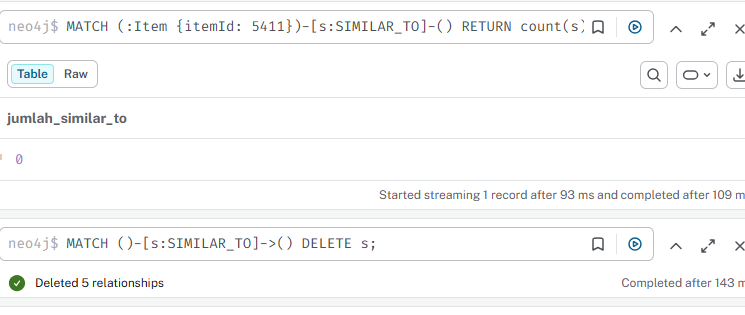

In [21]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1246).png"))

### Graf Sebelum

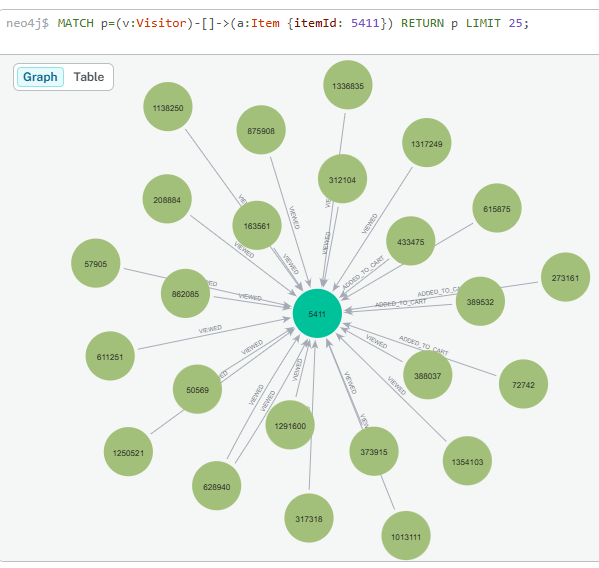

In [22]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1247).png"))

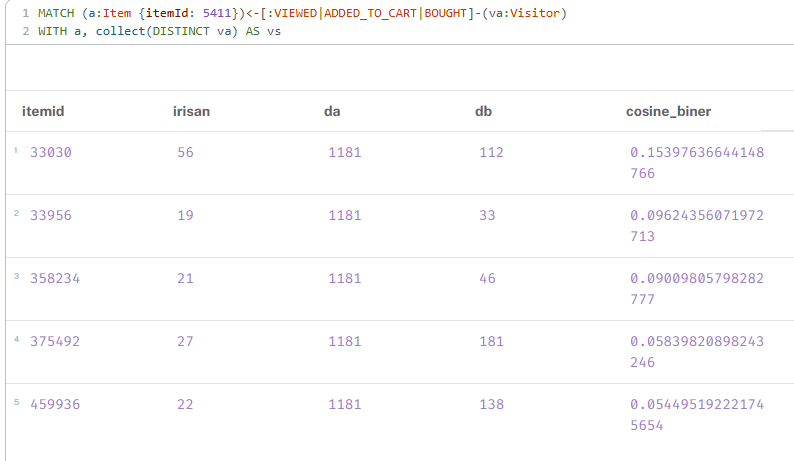

In [25]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1248).png"))

#### (b) Menuliskan kembali nilai similarity ke graf

(Versi utama dijalankan di Neo4j Browser; sel notebook ini hanya aktif bila `TULIS_KE_NEO4J = True`.) Nilai dari tabel No. 7 ditulis sebagai relasi `(:Item)-[:SIMILAR_TO {cosine_similarity: ...}]->(:Item)`. `MERGE` dipakai agar menjalankan sel dua kali tidak menggandakan relasi.

In [32]:
Q_WRITE = """
UNWIND $pairs AS pair
MATCH (s:Item {itemId: pair.source_id})
MATCH (t:Item {itemId: pair.target_id})
MERGE (s)-[r:SIMILAR_TO]->(t)
SET r.cosine_similarity = pair.similarity
RETURN count(r) AS jumlah_relasi
"""
pairs = [
    {"source_id": REF_ITEM, "target_id": int(r.itemid), "similarity": float(r.cosine_similarity)}
    for r in result_similarity.itertuples()
]
if TULIS_KE_NEO4J:
    display(cypher(Q_WRITE, pairs=pairs))
else:
    print("OUTPUT.")

Q_READ = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS sumber, b.itemId AS target, s.cosine_similarity AS cosine_similarity
ORDER BY s.cosine_similarity DESC
LIMIT 5
"""
print("Hasil query dari graf (5 similarity tertinggi yang tersimpan):")
display(cypher(Q_READ, ref=REF_ITEM))

OUTPUT.
Hasil query dari graf (5 similarity tertinggi yang tersimpan):


,sumber,target,cosine_similarity
0,5411,33030,0.153976
1,5411,33956,0.096244
2,5411,358234,0.090098
3,5411,375492,0.058398
4,5411,459936,0.054495


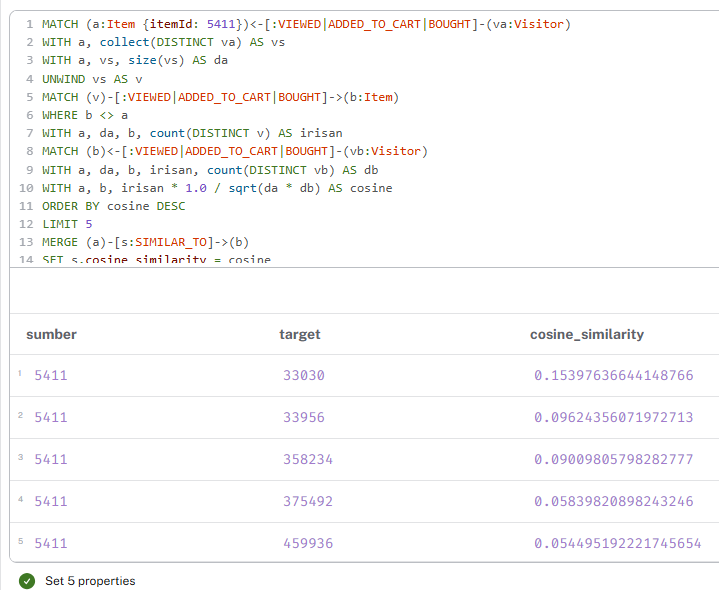

In [42]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1251).png"))

**Sesudah:** jumlah relasi `SIMILAR_TO` pada item acuan harus 5.

In [33]:
print("SESUDAH similarity ditulis ke graf:")
display(cypher(Q_COUNT, ref=REF_ITEM))
print()

SESUDAH similarity ditulis ke graf:


,jumlah_relasi_similar_to
0,5


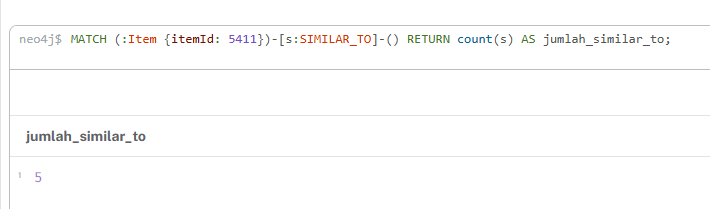

In [43]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1252).png"))

### Graf Sesudah

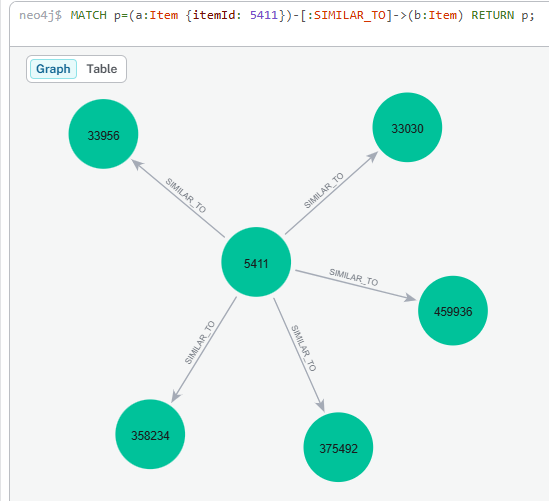

In [34]:
display(Image(filename="c:\\Users\\DELL\\OneDrive\\Gambar\\Screenshot\\Screenshot (1249).png"))

Visualisasi networkx yang setara dengan screenshot Neo4j: kiri = sebelum (hanya relasi user-item), kanan = sesudah (ditambah relasi `SIMILAR_TO`).

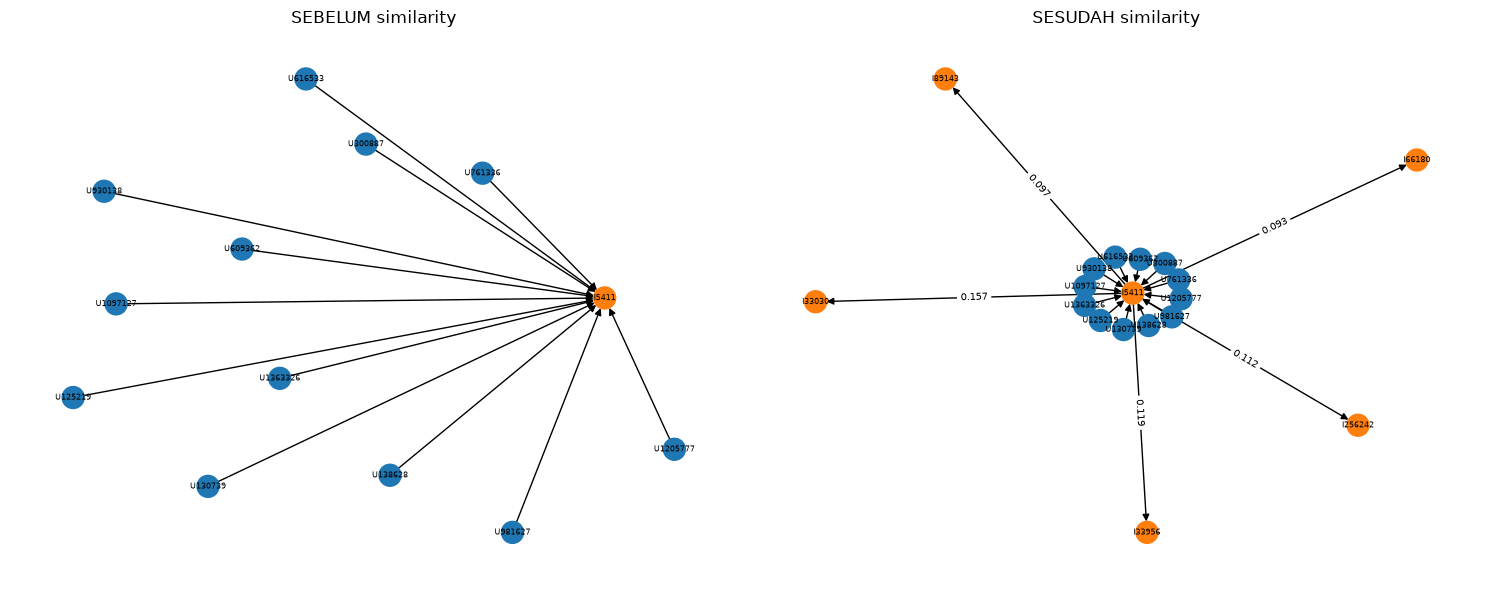

In [35]:
rng = np.random.default_rng(SEED)
pengguna_ref = VSM_csc[:, ref_idx].nonzero()[0]
sampel_ref = rng.choice(pengguna_ref, size=min(12, len(pengguna_ref)), replace=False)

G0 = nx.DiGraph()
for u in sampel_ref:
    G0.add_edge(f"U{visitor_ids[u]}", f"I{REF_ITEM}")

G1 = G0.copy()
for r in result_similarity.itertuples():
    G1.add_edge(f"I{REF_ITEM}", f"I{int(r.itemid)}", w=round(r.cosine_similarity, 3))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, g, judul in [(ax[0], G0, "SEBELUM similarity"), (ax[1], G1, "SESUDAH similarity")]:
    pos = nx.spring_layout(g, seed=SEED)
    warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in g]
    nx.draw_networkx(g, pos, node_color=warna, node_size=250, font_size=6, ax=a, arrows=True)
    if g is G1:
        nx.draw_networkx_edge_labels(g, pos, edge_labels={(s, t): d["w"] for s, t, d in g.edges(data=True) if "w" in d},
                                     font_size=7, ax=a)
    a.set_title(judul); a.axis("off")
plt.tight_layout(); plt.show()

## 2.2 Analytics

### No. 1: Rekomendasi KNN untuk satu user acak

**Metode (user-based KNN, k = 5):**
1. Hitung *cosine similarity* user target terhadap seluruh user (VSM berbobot).
2. Ambil **5 tetangga terdekat** yang menyumbang minimal satu *item baru* (belum pernah disentuh user target). Tetangga yang seluruh itemnya sudah dilihat user target tidak bisa menyumbang rekomendasi, jadi dilewati. Urutan seri dibuat deterministik dengan `kind="stable"`.
3. Skor item = jumlah (bobot interaksi tetangga × similarity tetangga). Item yang sudah pernah disentuh user target dibuang.
4. Item dengan skor tertinggi menjadi iklan.

**Catatan:** user yang hanya memiliki satu item punya cosine = 1 dengan siapa pun yang menyentuh item yang sama, berapa pun bobotnya, sehingga banyak yang seri. Karena itu user target dipilih dari mereka yang punya minimal 3 item unik di training.

**Pemilihan user acak (reproducible):** kandidat adalah user yang (i) ada di training dengan >= 3 item unik, dan (ii) muncul di testing dengan minimal satu item **baru** (belum ada di riwayat training). Kandidat diurutkan, lalu dipilih dengan `np.random.default_rng(42)`.

In [36]:
VN = normalize(VSM, norm="l2", axis=1)                      # VSM user dinormalisasi sekali saja
test_items_by_user = test_df.groupby("visitorid")["itemid"].apply(lambda s: set(map(int, s)))


def items_seen(ui):
    return {int(item_ids[j]) for j in VSM[ui].indices}


def truth_baru(user_id):
    """Item testing yang BELUM pernah disentuh user di training (yang mungkin direkomendasikan)."""
    return test_items_by_user[user_id] - items_seen(visitor_to_idx[user_id])


kandidat = sorted(
    int(u) for u in test_items_by_user.index
    if u in visitor_to_idx
    and items_per_visitor[visitor_to_idx[u]] >= 3
    and len(truth_baru(int(u))) > 0
)
print("Jumlah kandidat user:", len(kandidat))

target_user = int(np.random.default_rng(SEED).choice(kandidat))
print("User target (seed =", SEED, "):", target_user)

Jumlah kandidat user: 2558
User target (seed = 42 ): 124780


In [37]:
def knn_neighbors(ui, k=5):
    """k tetangga terdekat yang menyumbang minimal satu item baru."""
    seen_cols = VSM[ui].indices
    sim = (VN @ VN[ui].T).toarray().ravel()
    sim[ui] = -1                                              # bukan tetangga dirinya sendiri
    overlap = np.asarray(VSM_csc[:, seen_cols].sum(axis=1)).ravel()   # berapa item tetangga yang sudah dilihat target
    menyumbang_baru = items_per_visitor > overlap
    cand = np.flatnonzero((sim > 0) & menyumbang_baru)
    nb = cand[np.argsort(-sim[cand], kind="stable")[:k]]
    return nb, sim, set(seen_cols)


def recommend_knn(user_id, k=5, n_rec=5):
    ui = visitor_to_idx[int(user_id)]
    nb, sim, seen = knn_neighbors(ui, k)
    if len(nb) == 0:
        return [], nb, sim
    skor = np.asarray(VSM[nb].multiply(sim[nb][:, None]).sum(axis=0)).ravel()
    skor[list(seen)] = 0
    c = np.flatnonzero(skor > 0)
    top = c[np.argsort(-skor[c], kind="stable")[:n_rec]]
    return [int(item_ids[j]) for j in top], nb, sim

#### (a) Skrip KNN, hasil tetangga untuk user target

In [38]:
K = 5
ui_target = visitor_to_idx[target_user]
recs5, nb, sim = recommend_knn(target_user, k=K, n_rec=5)

print("User target:", target_user, "| item di training:", sorted(items_seen(ui_target)))
tabel_tetangga = pd.DataFrame({
    "visitorid": visitor_ids[nb],
    "cosine_similarity": sim[nb],
    "jumlah_item": items_per_visitor[nb],
    "item_baru_yang_disumbang": [
        sorted(int(item_ids[j]) for j in VSM[i].indices if int(item_ids[j]) not in items_seen(ui_target))
        for i in nb
    ],
})
print(f"\n{K} tetangga terdekat:")
display(tabel_tetangga)

User target: 124780 | item di training: [4377, 181067, 224348]

5 tetangga terdekat:


,visitorid,cosine_similarity,jumlah_item,item_baru_yang_disumbang
0,928961,0.547723,2,[260384]
1,497432,0.529813,4,"[166691, 305496, 448839]"
2,323454,0.522233,3,"[246361, 448839]"
3,1246870,0.522233,6,"[16673, 128443, 192792, 256270, 450455]"
4,200831,0.516398,2,[418619]


#### (b) Tiga item yang diiklankan (k = 5)

In [39]:
iklan = recs5[:3]
print("3 item yang diiklankan untuk user", target_user, ":", iklan)

# skor tiap item iklan
skor_tabel = []
for it in iklan:
    j = item_to_idx[it]
    skor_tabel.append({"itemid": it, "skor": float(VSM[nb][:, j].multiply(sim[nb][:, None]).sum())})
display(pd.DataFrame(skor_tabel))

3 item yang diiklankan untuk user 124780 : [448839, 128443, 260384]


,itemid,skor
0,448839,1.052046
1,128443,1.044466
2,260384,0.547723


### No. 2: Hit@5 dan NDCG@5 untuk user target

*Ground truth* = item yang disentuh user target di data **testing** dan belum ada di riwayat training. Item yang sudah pernah dilihat user tidak mungkin direkomendasikan, sehingga tidak adil dihitung sebagai target.

- **Hit@5** = 1 bila minimal satu item rekomendasi (top-5) ada di ground truth, selain itu 0.
- **DCG@5** = Σ rel_i / log₂(i + 1), dengan i adalah posisi (mulai 1) dan rel_i = 1 bila item di posisi i relevan.
- **IDCG@5** = DCG terbaik yang mungkin (semua item relevan di posisi teratas).
- **NDCG@5** = DCG@5 / IDCG@5.

In [40]:
def hit_at_k(rec, truth, k=5):
    return int(any(x in truth for x in rec[:k]))


def ndcg_at_k(rec, truth, k=5):
    dcg = sum(1 / np.log2(i + 2) for i, x in enumerate(rec[:k]) if x in truth)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0


truth = truth_baru(target_user)
print("User target       :", target_user)
print("Ground truth      :", sorted(truth))
print("Rekomendasi (3)   :", iklan)
print("Irisan            :", sorted(set(iklan) & truth))
print(f"Hit@5  (3 item iklan) : {hit_at_k(iklan, truth)}")
print(f"NDCG@5 (3 item iklan) : {ndcg_at_k(iklan, truth):.4f}")
print(f"Hit@5  (top-5 penuh)  : {hit_at_k(recs5, truth)}")
print(f"NDCG@5 (top-5 penuh)  : {ndcg_at_k(recs5, truth):.4f}")

User target       : 124780
Ground truth      : [86187, 193545, 292444]
Rekomendasi (3)   : [448839, 128443, 260384]
Irisan            : []
Hit@5  (3 item iklan) : 0
NDCG@5 (3 item iklan) : 0.0000
Hit@5  (top-5 penuh)  : 0
NDCG@5 (top-5 penuh)  : 0.0000


 nilai 0 untuk satu user adalah hal yang wajar pada data ini. Data sangat *sparse* (hanya sekitar 5,8% user testing yang juga ada di training, dan median item relevan per user hanya 1), sedangkan rekomendasi hanya 3 sampai 5 item dari sekitar 170 ribu item. Satu user hanyalah contoh kasus, jadi bagian berikut mengevaluasi banyak user agar kesimpulannya lebih kuat.

### Evaluasi tambahan: 300 user acak dan pembanding baseline

Untuk menilai apakah KNN benar-benar bekerja, 300 user diambil secara acak (seed tetap) dari kandidat yang sama, lalu dibandingkan dengan **baseline popularitas** (merekomendasikan item terpopuler yang belum pernah dilihat user).

In [41]:
urutan_populer = np.argsort(-visitors_per_item, kind="stable")[:300]       # indeks item terpopuler


def recommend_populer(user_id, n_rec=5):
    seen = set(VSM[visitor_to_idx[int(user_id)]].indices)
    return [int(item_ids[j]) for j in urutan_populer if j not in seen][:n_rec]


sampel = np.random.default_rng(SEED).choice(kandidat, size=300, replace=False)
baris = []
for u in sampel:
    u = int(u)
    tr = truth_baru(u)
    rk, _, _ = recommend_knn(u, k=5, n_rec=5)
    pp = recommend_populer(u, 5)
    baris.append({
        "visitorid": u, "n_truth": len(tr),
        "knn5_hit": hit_at_k(rk, tr), "knn5_ndcg": ndcg_at_k(rk, tr),
        "knn3_hit": hit_at_k(rk[:3], tr), "knn3_ndcg": ndcg_at_k(rk[:3], tr),
        "pop5_hit": hit_at_k(pp, tr), "pop5_ndcg": ndcg_at_k(pp, tr),
        "ada_rekomendasi": int(len(rk) > 0),
    })
evaluation_df = pd.DataFrame(baris)

ringkasan = pd.DataFrame({
    "metode": ["KNN k=5 (top-5)", "KNN k=5 (3 item iklan)", "Baseline popularitas (top-5)"],
    "Hit@5": [evaluation_df["knn5_hit"].mean(), evaluation_df["knn3_hit"].mean(), evaluation_df["pop5_hit"].mean()],
    "NDCG@5": [evaluation_df["knn5_ndcg"].mean(), evaluation_df["knn3_ndcg"].mean(), evaluation_df["pop5_ndcg"].mean()],
    "jumlah_user_hit": [evaluation_df["knn5_hit"].sum(), evaluation_df["knn3_hit"].sum(), evaluation_df["pop5_hit"].sum()],
})
print("Jumlah user dievaluasi:", len(evaluation_df),
      "| user tanpa rekomendasi:", int((evaluation_df["ada_rekomendasi"] == 0).sum()))
display(ringkasan.round(4))

Jumlah user dievaluasi: 300 | user tanpa rekomendasi: 3


,metode,Hit@5,NDCG@5,jumlah_user_hit
0,KNN k=5 (top-5),0.0200,0.0066,6
1,KNN k=5 (3 item iklan),0.0133,0.0043,4
2,Baseline popularitas (top-5),0.0000,0.0000,0
